В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 5

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['XMR', 'BTC', 'DOT', 'ADA', 'XRP', 'XLM', 'SOL', 'DOGE', 'LINK', 'ETH']

In [6]:
# strategy={"extra_buy_amount": 500}
strategy={}

04:11:49 - cmdstanpy - INFO - Chain [1] start processing
04:11:49 - cmdstanpy - INFO - Chain [1] done processing


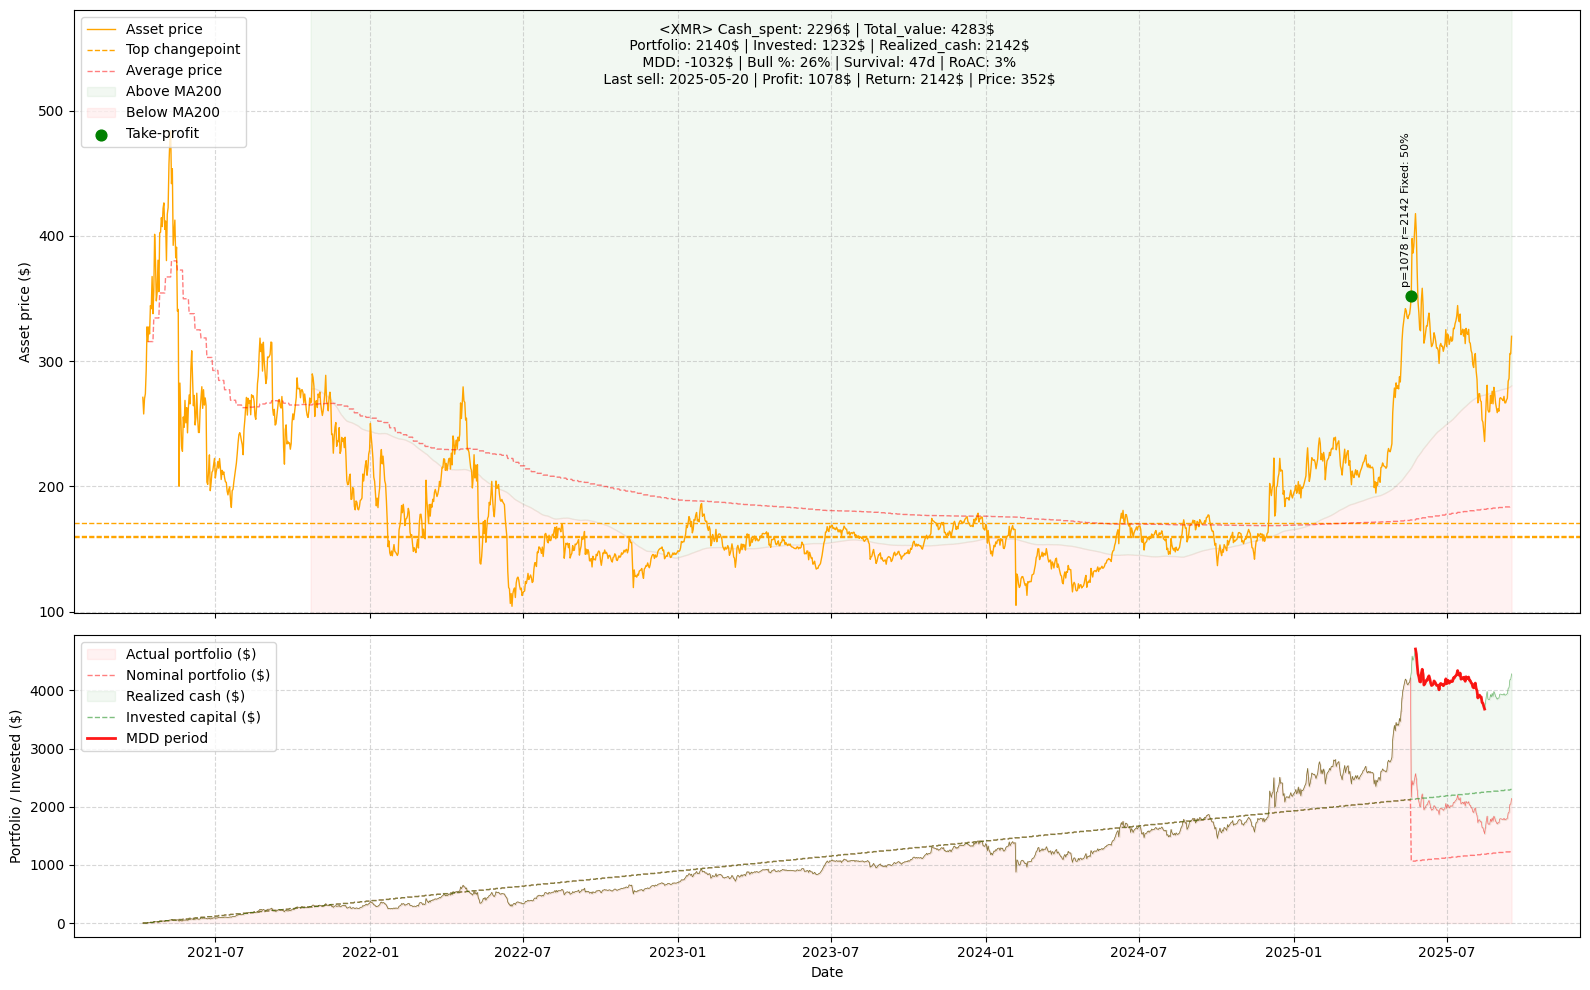

04:11:49 - cmdstanpy - INFO - Chain [1] start processing
04:11:50 - cmdstanpy - INFO - Chain [1] done processing


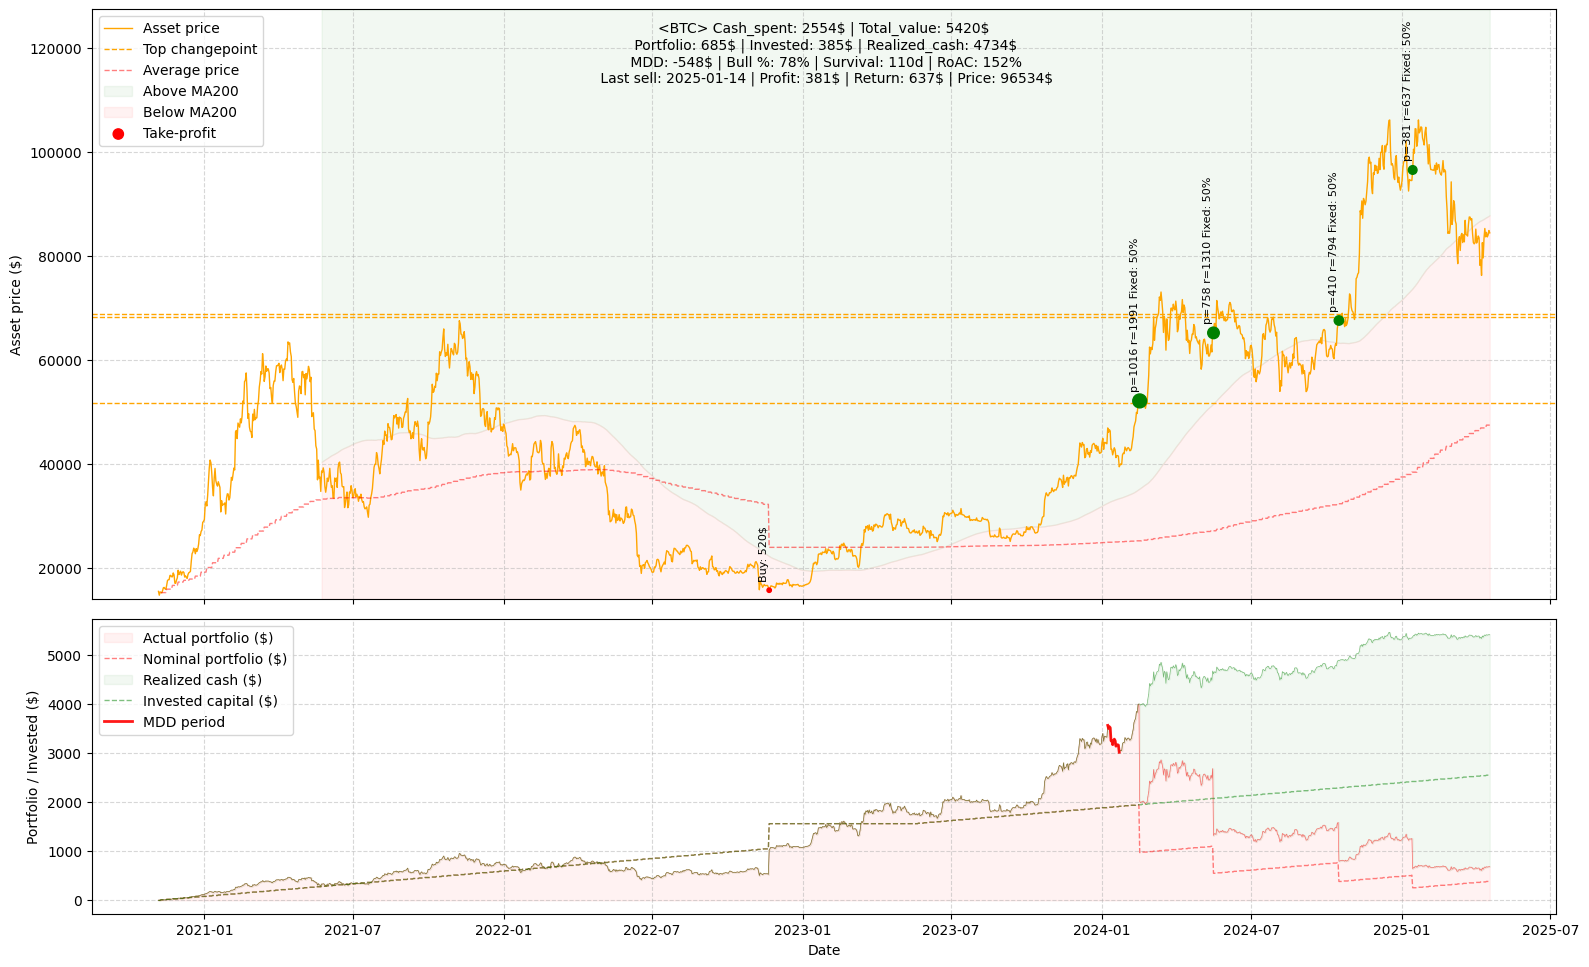

04:11:50 - cmdstanpy - INFO - Chain [1] start processing
04:11:50 - cmdstanpy - INFO - Chain [1] done processing


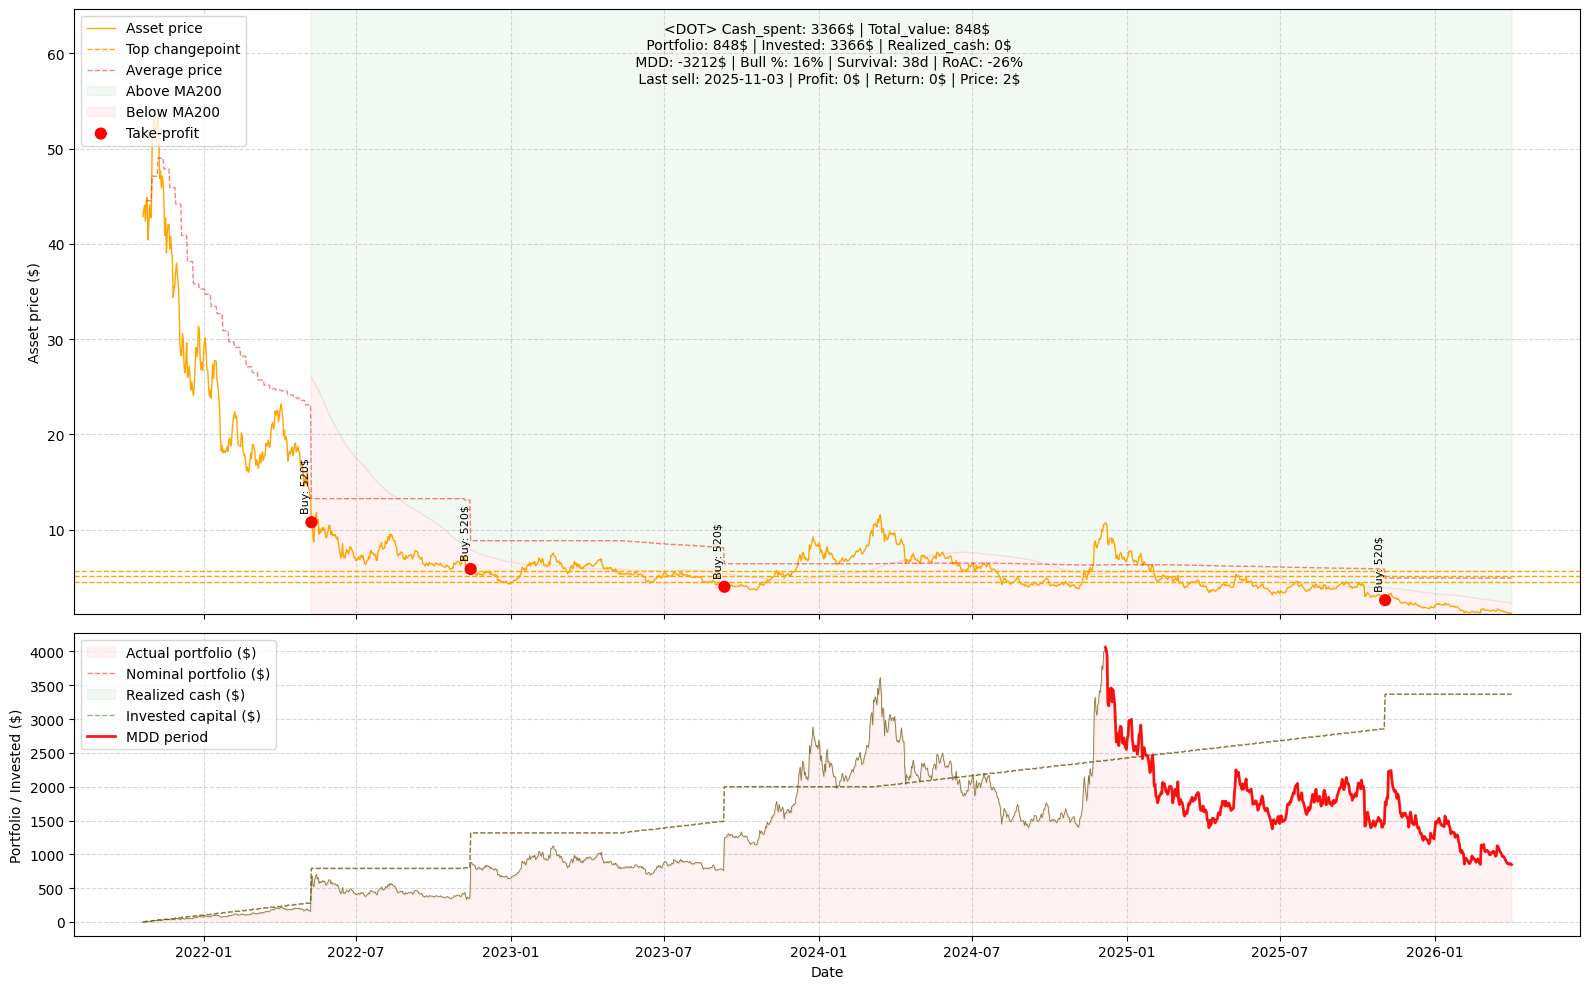

04:11:51 - cmdstanpy - INFO - Chain [1] start processing
04:11:51 - cmdstanpy - INFO - Chain [1] done processing


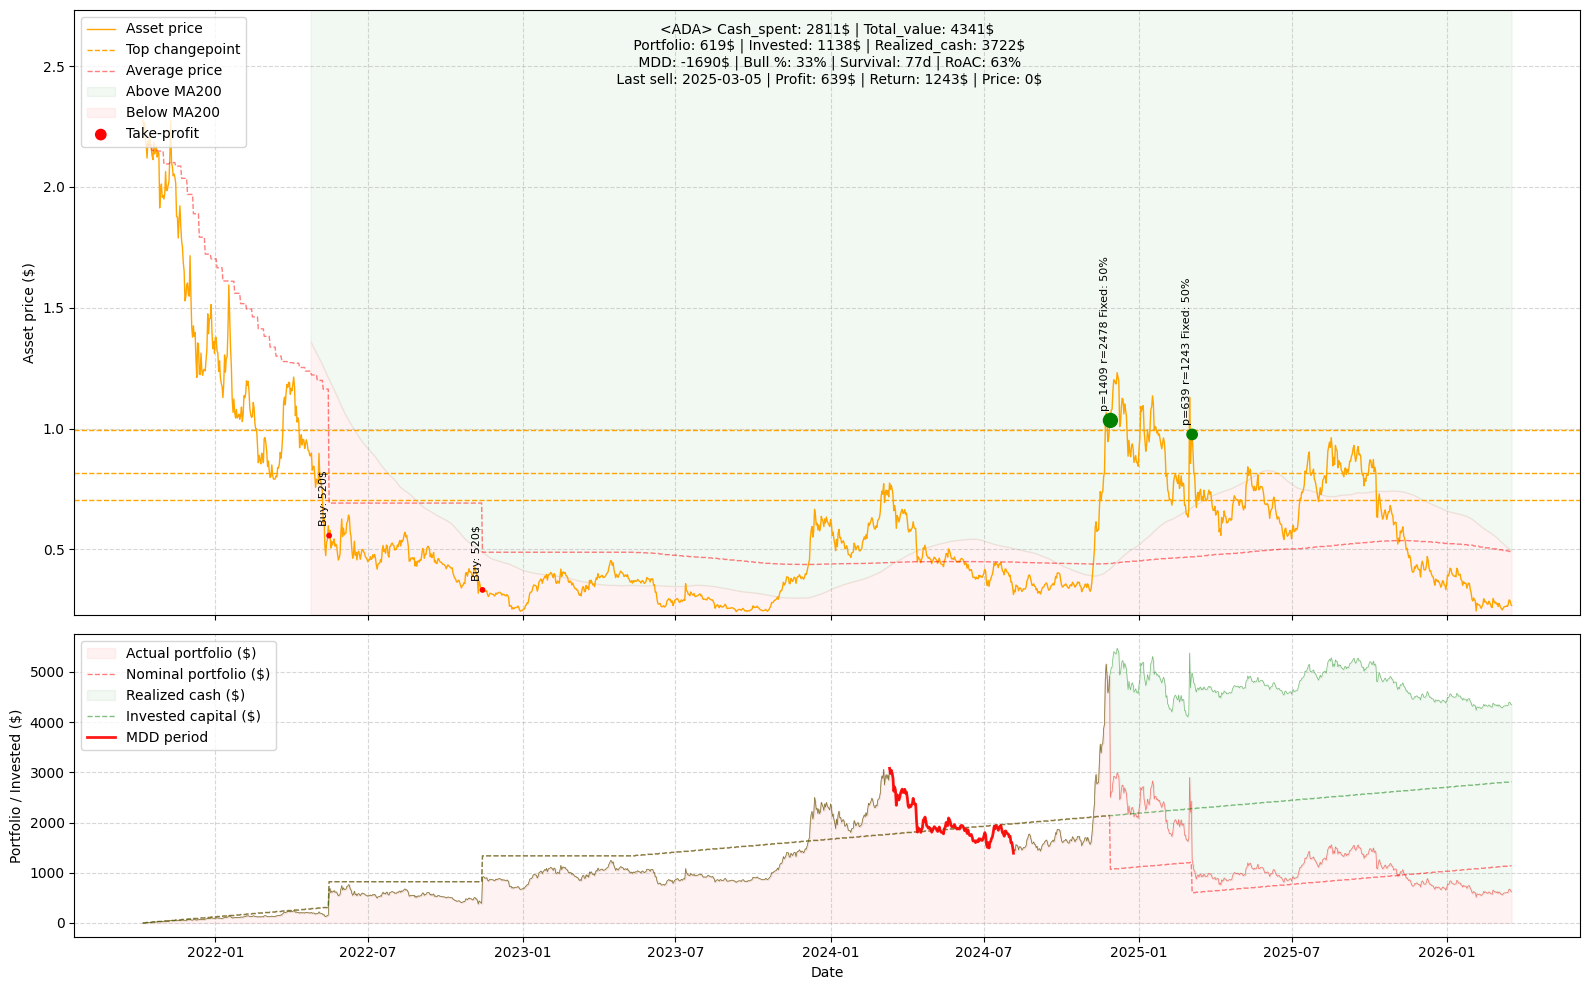

04:11:52 - cmdstanpy - INFO - Chain [1] start processing
04:11:52 - cmdstanpy - INFO - Chain [1] done processing


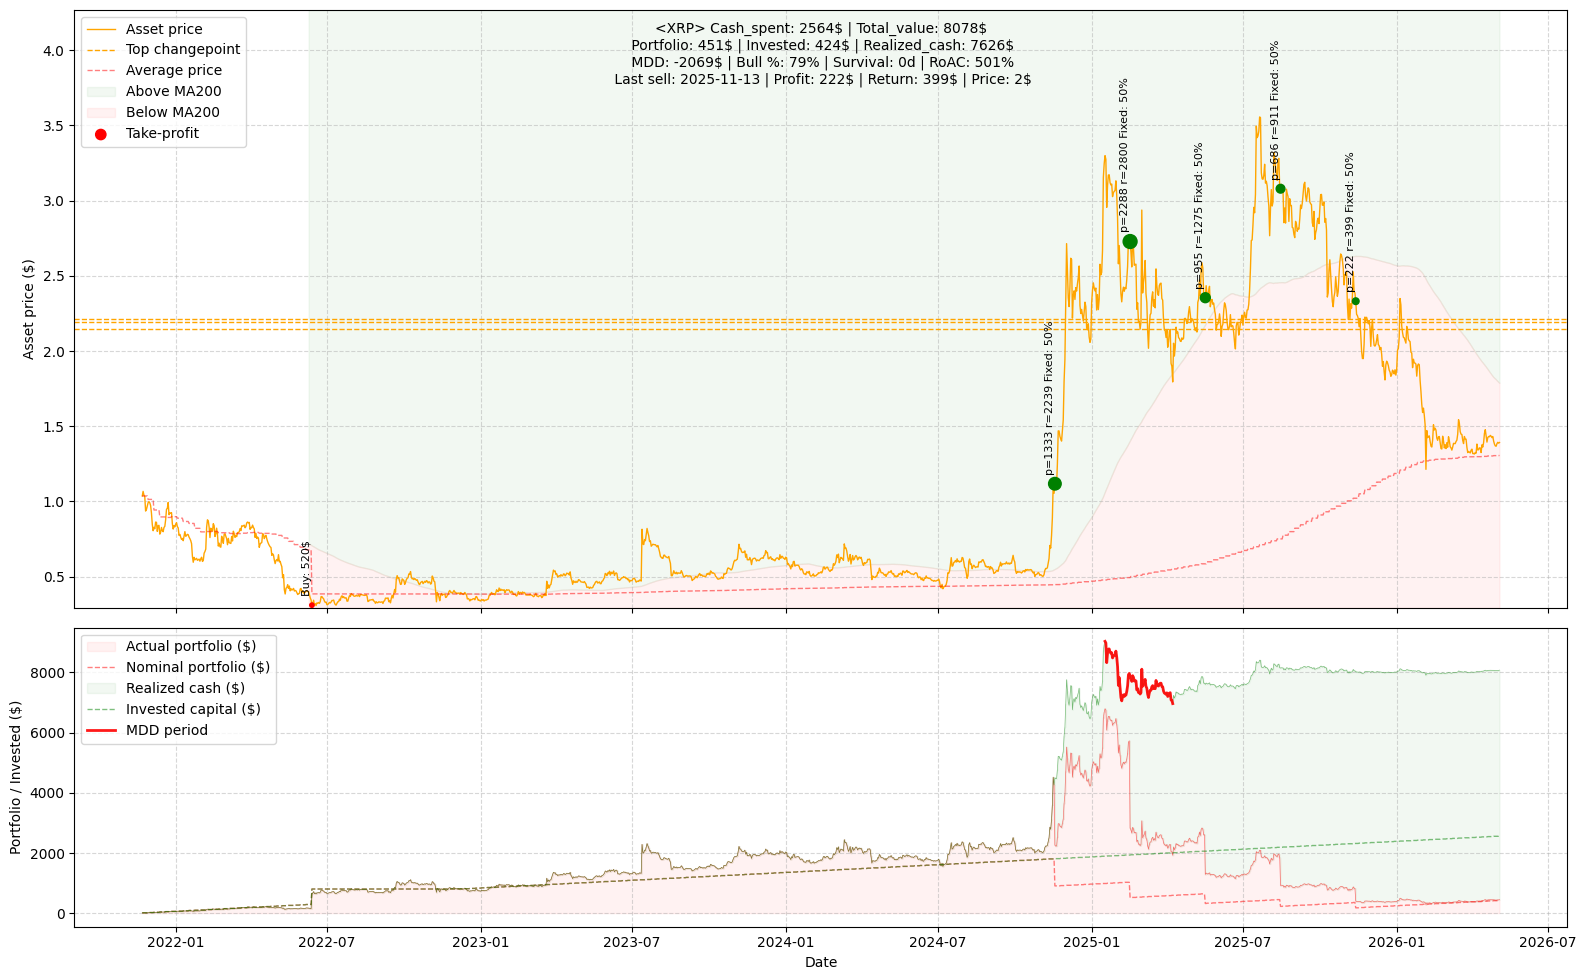

04:11:52 - cmdstanpy - INFO - Chain [1] start processing
04:11:52 - cmdstanpy - INFO - Chain [1] done processing


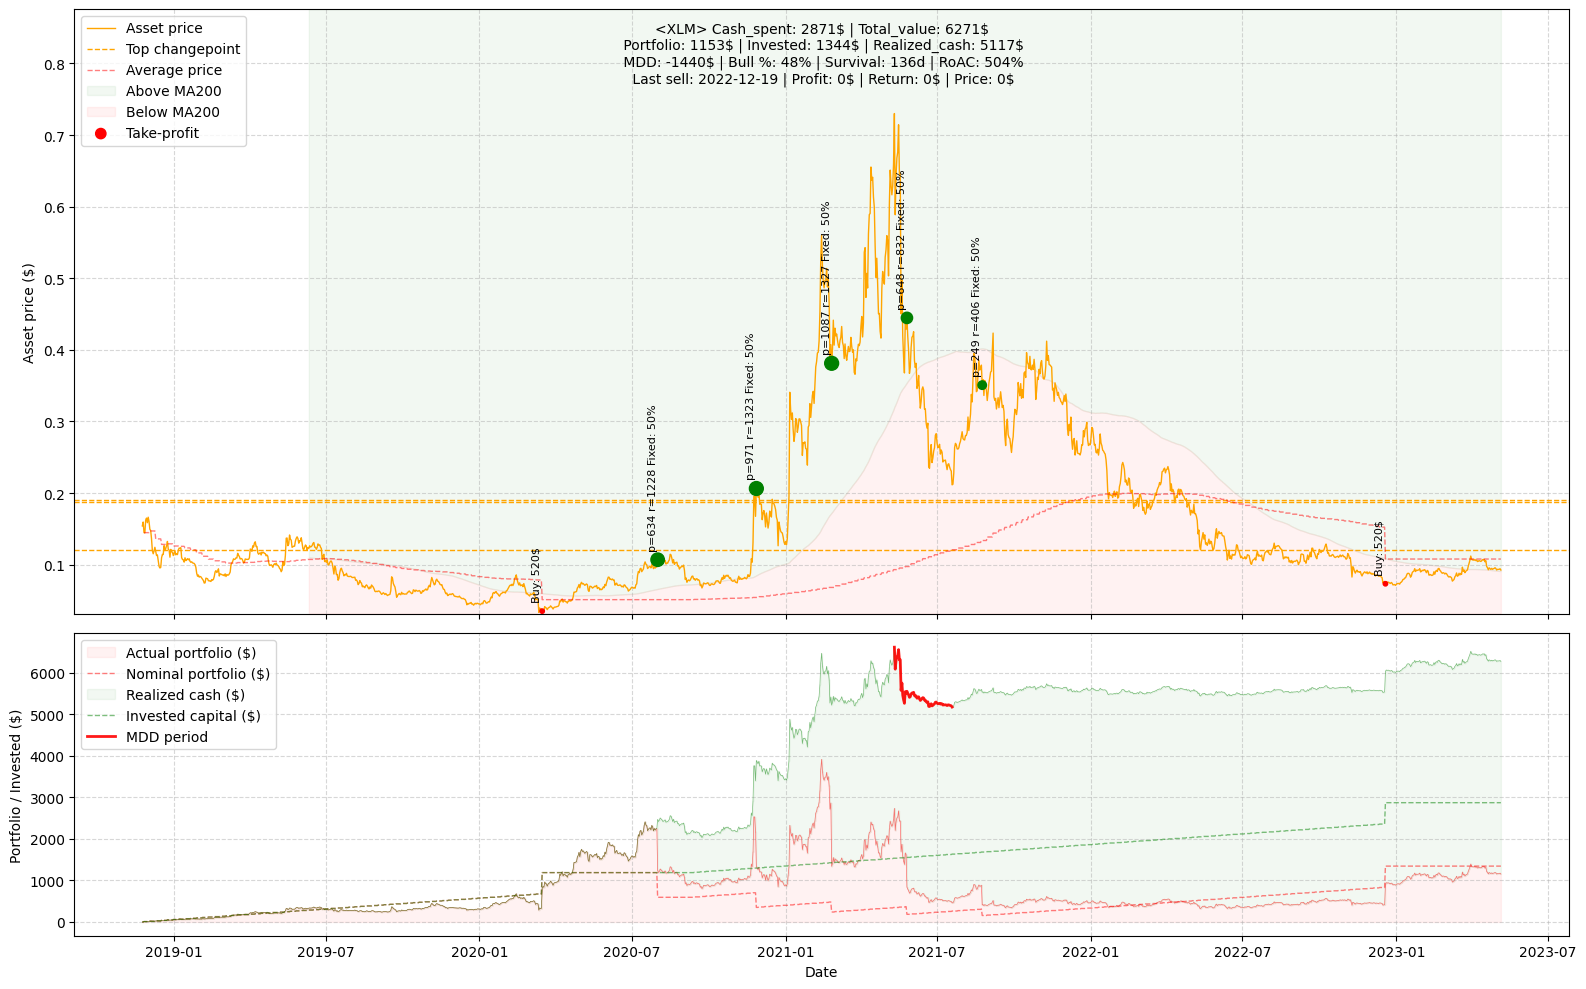

04:11:53 - cmdstanpy - INFO - Chain [1] start processing
04:11:53 - cmdstanpy - INFO - Chain [1] done processing


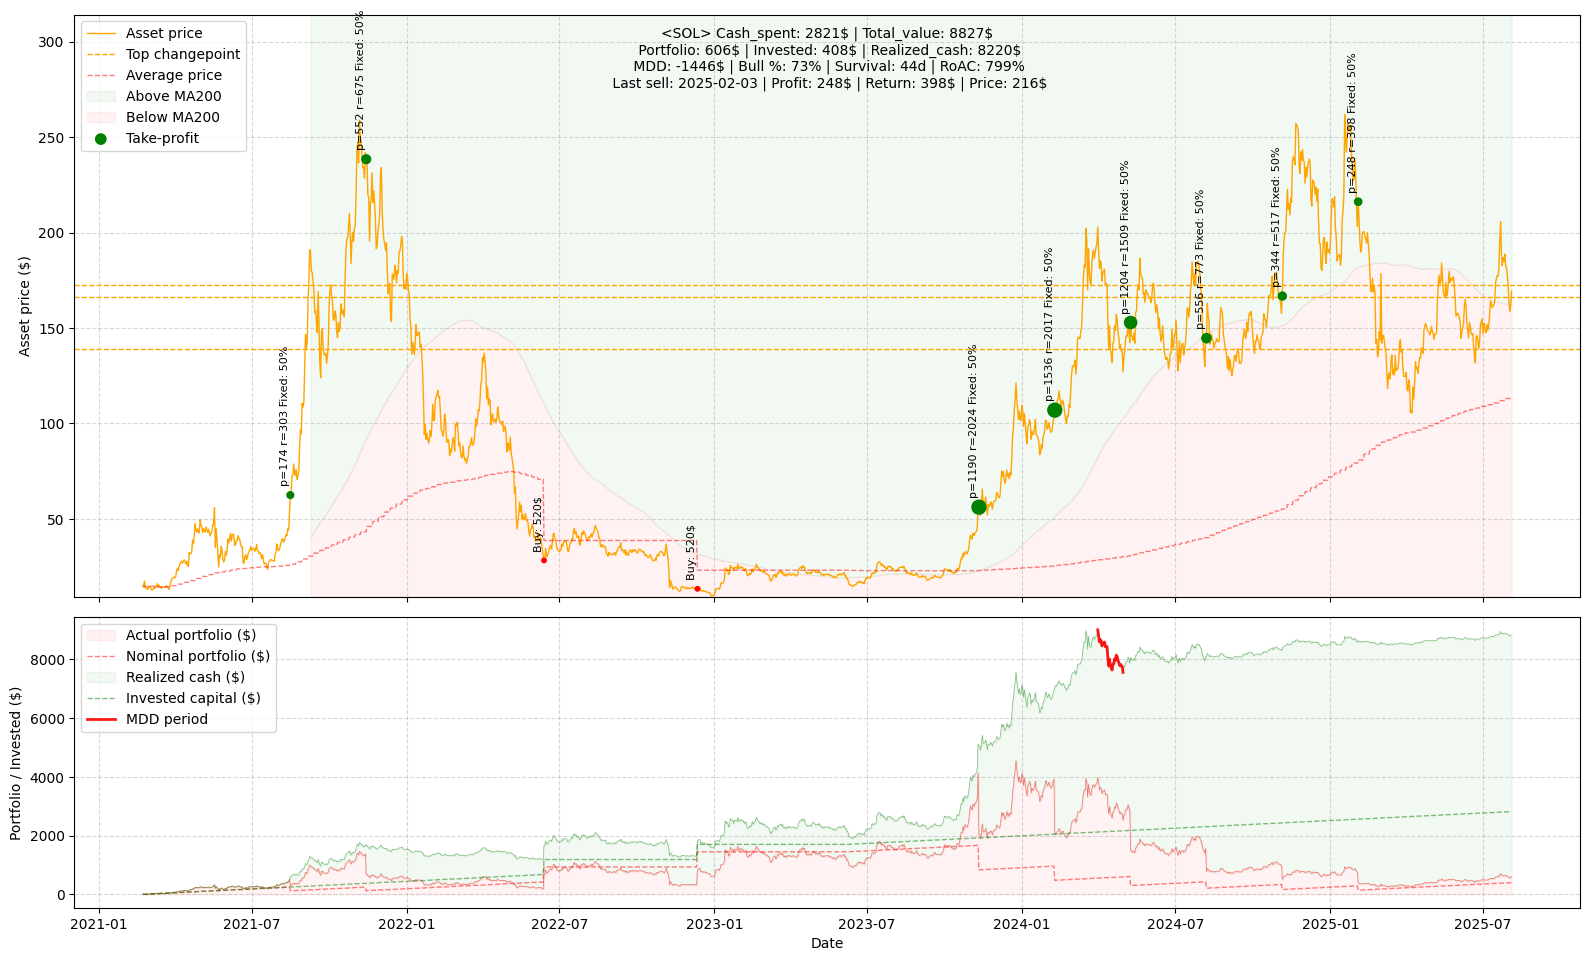

04:11:54 - cmdstanpy - INFO - Chain [1] start processing
04:11:54 - cmdstanpy - INFO - Chain [1] done processing


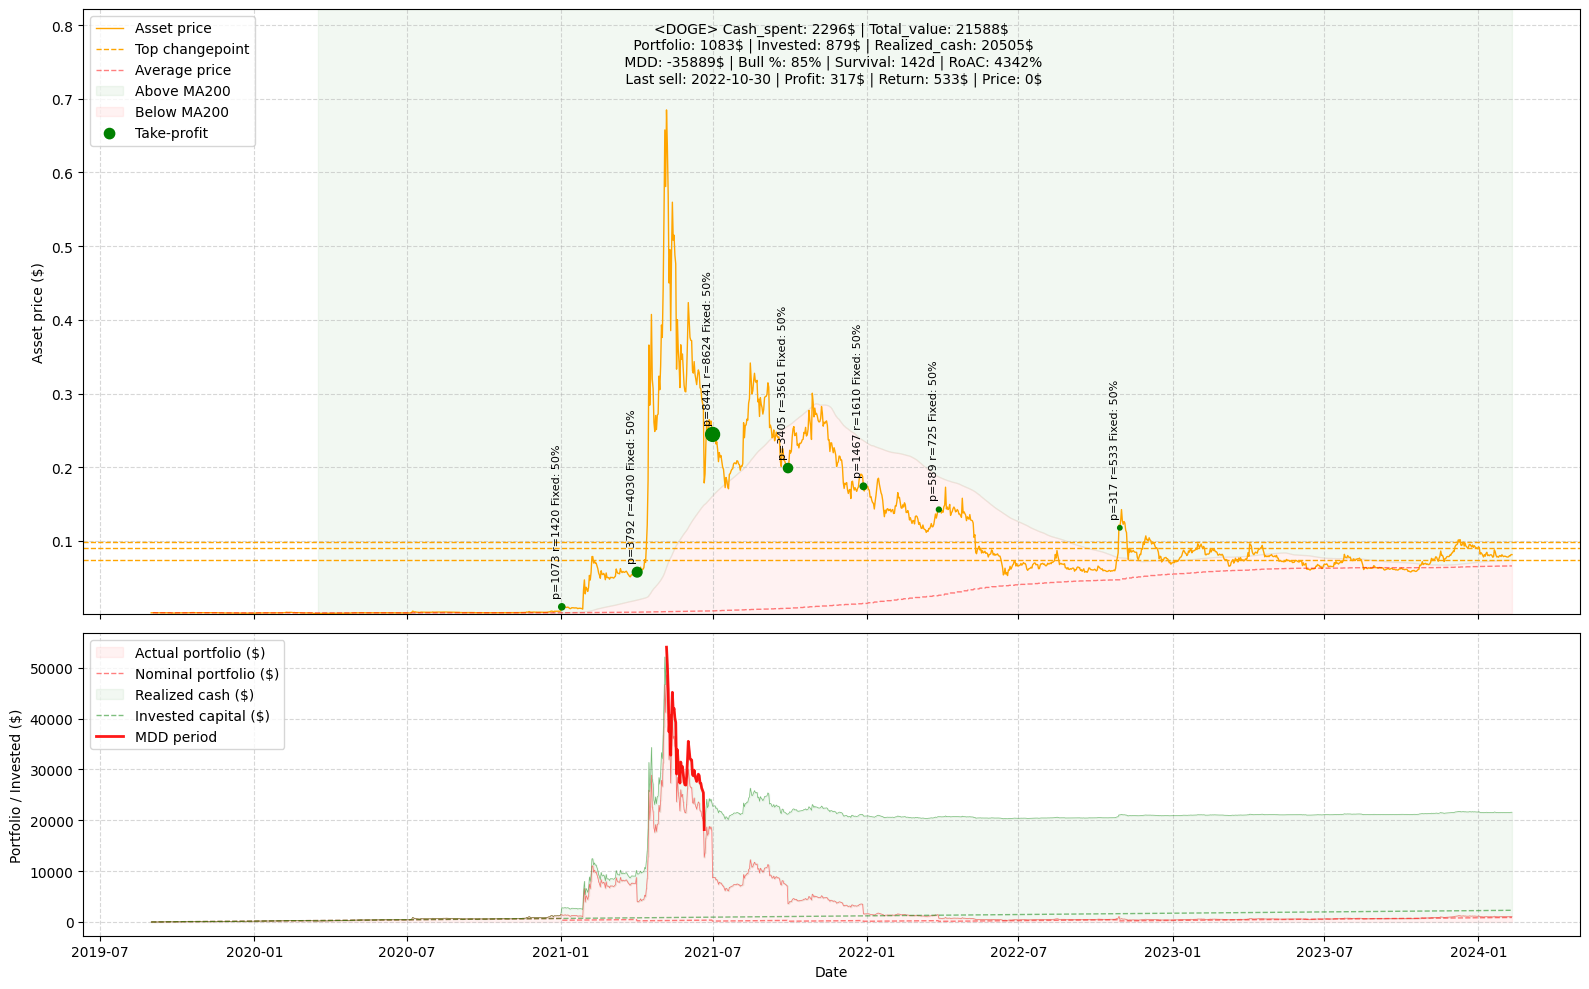

04:11:54 - cmdstanpy - INFO - Chain [1] start processing
04:11:55 - cmdstanpy - INFO - Chain [1] done processing


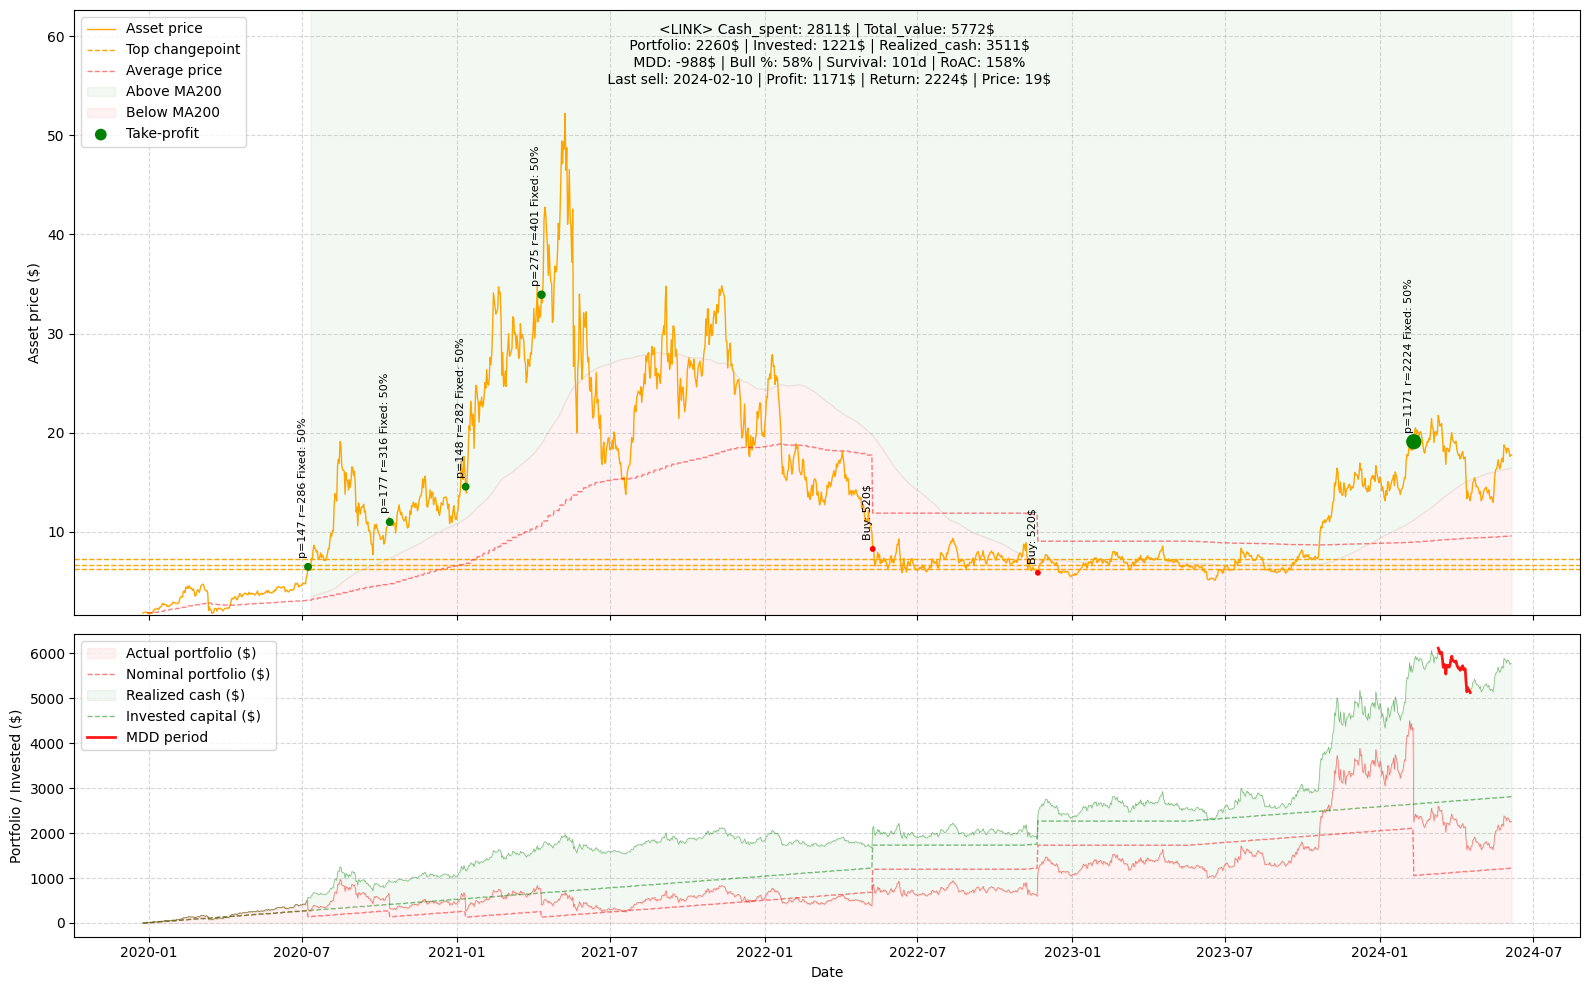

04:11:55 - cmdstanpy - INFO - Chain [1] start processing
04:11:55 - cmdstanpy - INFO - Chain [1] done processing


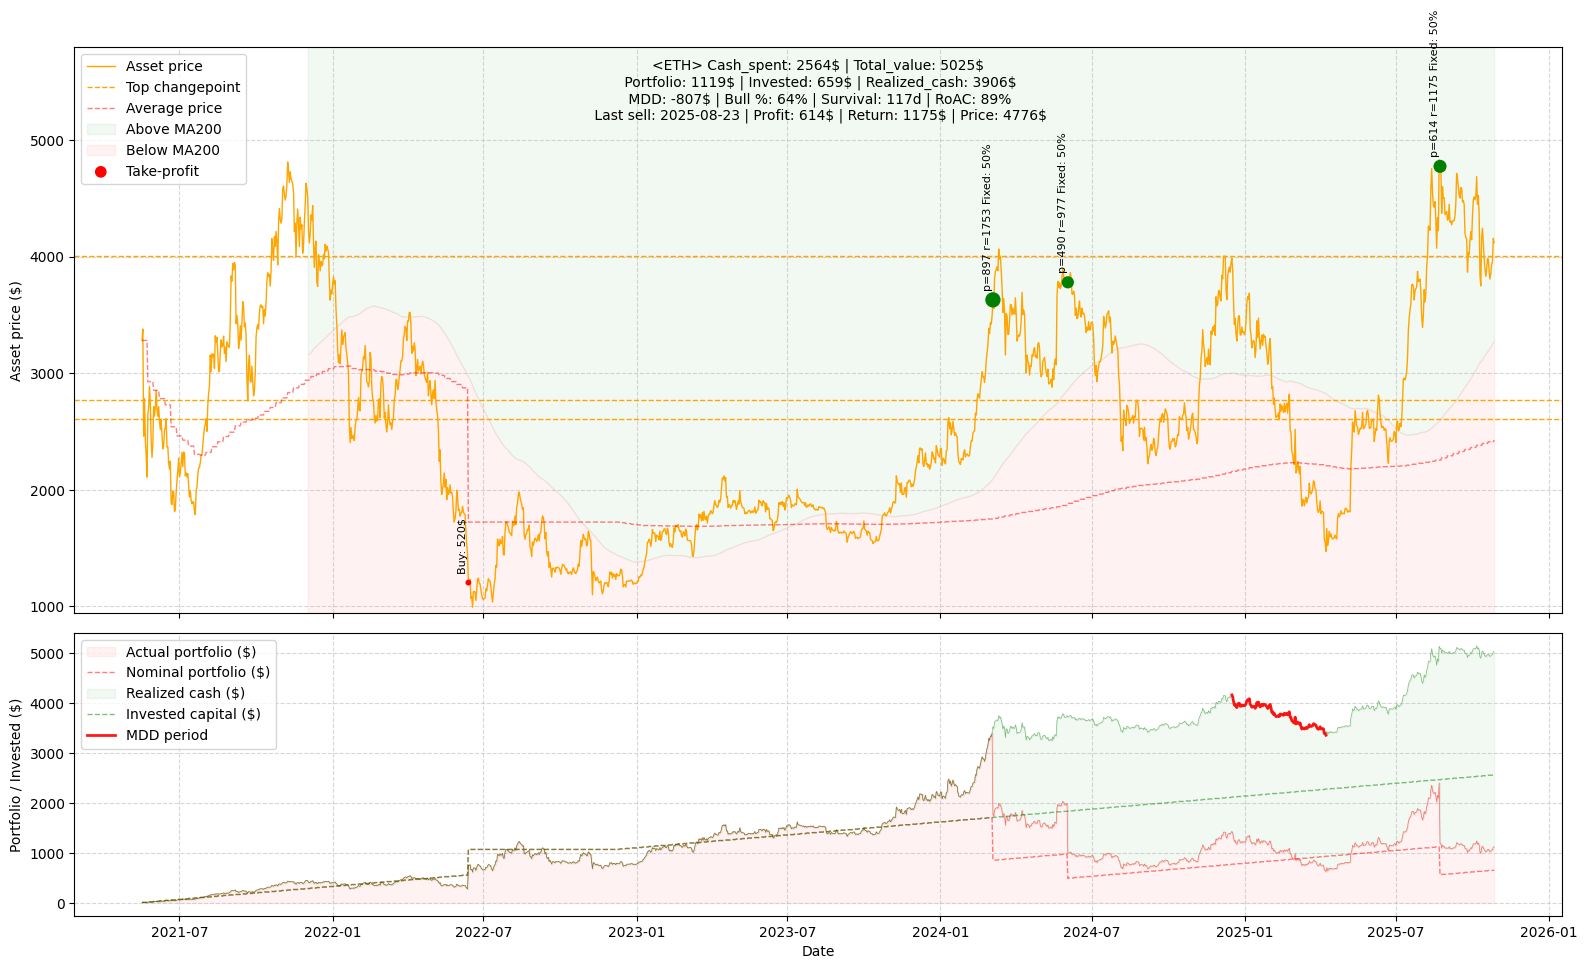

Total invested: $26954.00
Total return: $59483.00
Total value: $70453.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2021-05-17,3282.397705,0.003016,9.9000,9.9,0.0,0.0,0.000000,,9.900000,3282.397705,9.900000
2021-05-18,3380.070068,0.003016,9.9000,9.9,0.0,0.0,0.000000,,10.194588,3282.397705,10.194588
2021-05-19,2460.679199,0.003016,9.9000,9.9,0.0,0.0,0.000000,,7.421625,3282.397705,7.421625
2021-05-20,2784.294189,0.003016,9.9000,9.9,0.0,0.0,0.000000,,8.397676,3282.397705,8.397676
2021-05-21,2430.621338,0.003016,9.9000,9.9,0.0,0.0,0.000000,,7.330968,3282.397705,7.330968
...,...,...,...,...,...,...,...,...,...,...,...
2025-10-23,3856.026367,0.269218,649.6875,2554.2,0.0,0.0,3906.521186,,1038.110929,2413.241264,4944.632115
2025-10-24,3934.567383,0.269218,649.6875,2554.2,0.0,0.0,3906.521186,,1059.255568,2413.241264,4965.776754
2025-10-25,3953.470947,0.269218,649.6875,2554.2,0.0,0.0,3906.521186,,1064.344744,2413.241264,4970.865930


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1625)

In [10]:
metrics

{'Target': 'ETH',
 'Cash_spent': 2564,
 'Realized_cash': 3906,
 'Portfolio': 1119,
 'Invested': 659,
 'Total_value': 5025,
 'Bull_history': 64,
 'Avg_price': np.float64(2428.340867660935),
 'Num_take_profits': 4,
 'MDD': -807,
 'MA200_survival_days': 117.00000000000003,
 'RoAC': 89}